# Quickstart: image casting and fusion

This notebook shows the core idea of the method on **synthetic** data (no ADNI access needed):

1. Load a 3D MRI and PET volume
2. Normalise each scan
3. Cast each 3D scan into a 2D mosaic
4. Fuse MRI and PET

To train models, use the command-line tools described in the README.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mripet.synthetic import synthetic_pair
from mripet.preprocessing import normalise
from mripet.casting import cast_volume, slice_indices, GRID_PRESETS
from mripet.fusion import fuse_images

rng = np.random.default_rng(1)
mri, pet = synthetic_pair(converter=True, rng=rng)   # one synthetic 'converter' subject
print('Volume shape (z, y, x):', mri.shape)

Volume shape (z, y, x): (91, 109, 91)


## 1. Normalise
MRI is clipped to [0, 400] and scaled to [0, 1]; PET is min–max scaled per scan.

In [2]:
mri_n = normalise(mri, 'clip', vmin=0, vmax=400)
pet_n = normalise(pet, 'minmax')
print(f'MRI range {mri_n.min():.2f}–{mri_n.max():.2f}, PET range {pet_n.min():.2f}–{pet_n.max():.2f}')

MRI range 0.00–0.65, PET range 0.00–1.00


## 2. Slice selection for each grid size
Each n × n mosaic takes n² slices, starting at `top` and moving down by `step`.

In [3]:
for g, (top, step) in GRID_PRESETS.items():
    idx = slice_indices(g)
    print(f'{g}x{g}: top={top:>2}, step={step}, slices {idx[0]}..{idx[-1]} ({len(idx)} slices)')

1x1: top=44, step=0, slices 44..44 (1 slices)
2x2: top=60, step=10, slices 60..30 (4 slices)
3x3: top=65, step=5, slices 65..25 (9 slices)
4x4: top=68, step=3, slices 68..23 (16 slices)
5x5: top=68, step=2, slices 68..20 (25 slices)
6x6: top=62, step=1, slices 62..27 (36 slices)
7x7: top=72, step=1, slices 72..24 (49 slices)


## 3. Cast 3D → 2D

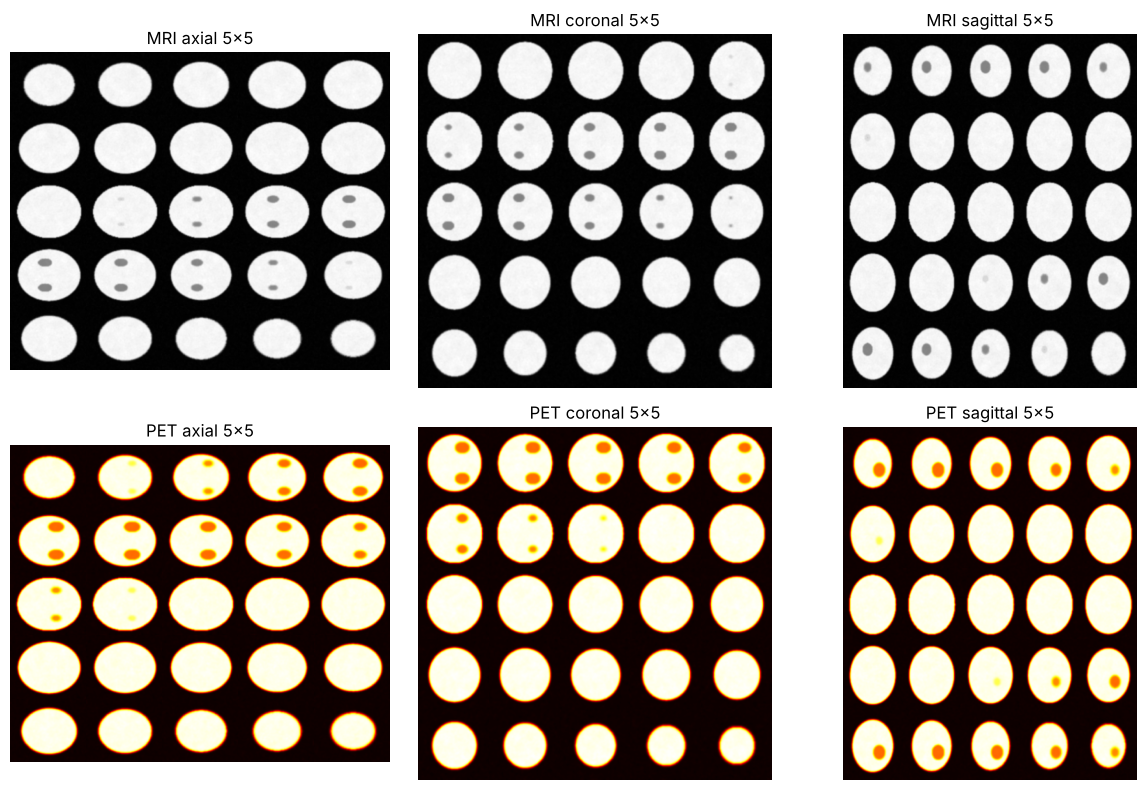

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for c, view in enumerate(['axial', 'coronal', 'sagittal']):
    axes[0, c].imshow(cast_volume(mri_n, view, 5), cmap='gray'); axes[0, c].set_title(f'MRI {view} 5x5')
    axes[1, c].imshow(cast_volume(pet_n, view, 5), cmap='hot');  axes[1, c].set_title(f'PET {view} 5x5')
for ax in axes.ravel(): ax.axis('off')
plt.tight_layout()

## 4. Image-level fusion
The `channels` method stacks MRI, PET and their mean as three channels of one image.

Fused input shape for the CNN: (1, 546, 546, 3)


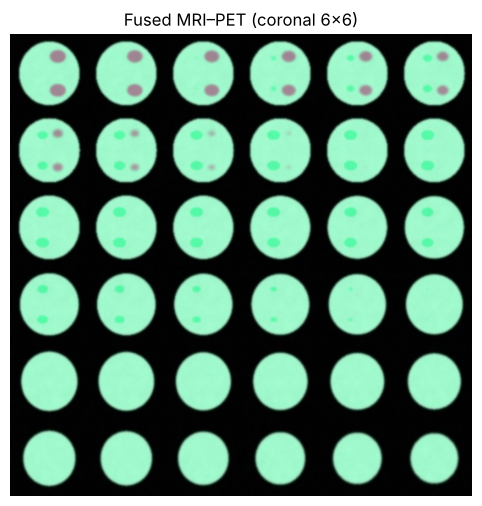

In [5]:
m = cast_volume(mri_n, 'coronal', 6)[None, ..., None]
p = cast_volume(pet_n, 'coronal', 6)[None, ..., None]
fused = fuse_images(m, p, 'channels')
print('Fused input shape for the CNN:', fused.shape)
plt.figure(figsize=(6, 6)); plt.imshow(fused[0]); plt.title('Fused MRI–PET (coronal 6x6)'); plt.axis('off');

## Next steps
```bash
python -m mripet.synthetic --out data/synthetic/raw --n-per-class 50
python -m mripet.io --config configs/synthetic.yaml
python -m mripet.train --config configs/synthetic.yaml
```